# Oversampling

### <i> Using SMOTE


<i> Creates synthetic samples specifically for the minority class, based on nearest neighbors. (Yes, KNN!) It's quite a useful way to synthesize data when you want to ensure the rarer combinations need representation.

In [1]:
# pip install imblearn
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTENC

# We're using SMOTEENC here because it spares us

df = pd.read_csv("../..//houses.csv")
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000.0,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000.0,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101.0,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000.0,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


Extracting time values from `date`

In [2]:
# Turn `date` into a datetime dtype.
# Use (regex) YUCK, to turn it into 
# the format we want.
df["date"] = pd.to_datetime(
    df["date"],
    format="%Y%m%dT%H%M%S"
)

# Extract the year, month and day.
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

# Drop `date` column. We got what we wanted from it.
df = df.drop(columns="date")

In [3]:
# We're not allowed to have use missing values for 
# ClusterCentroids. Let's drop them all here for the 
# sake of the example.
df = df.dropna()

---

### The problem

<Axes: xlabel='waterfront', ylabel='Count'>

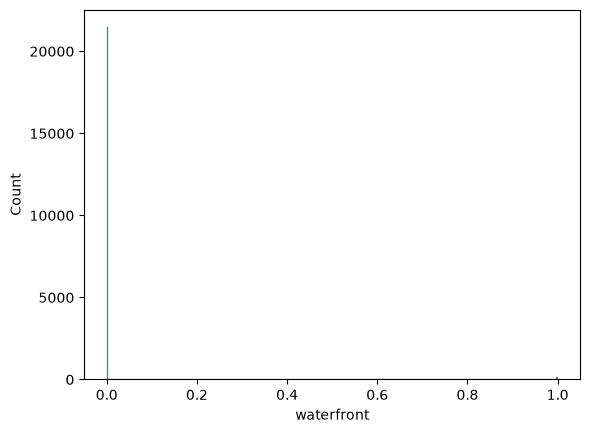

In [4]:
# Say that we're trying to make a machine learning model that
# predicts whether or not a home has a pool...

# And we look at this distribution and find that there's something very wrong.
sns.histplot(df, x="waterfront")

# The number of pools we have is massively underrepresented!
# And assume that we cannot collect any more data than this. 

# We have to create some data in order to represent the values better.

---

### SMOTE

In [5]:
df.shape

(21613, 23)

In [6]:
# Another x y split to prevent a data leakage
X = df.drop(columns="waterfront", axis=1)
y = df['waterfront']


<Axes: xlabel='waterfront', ylabel='Count'>

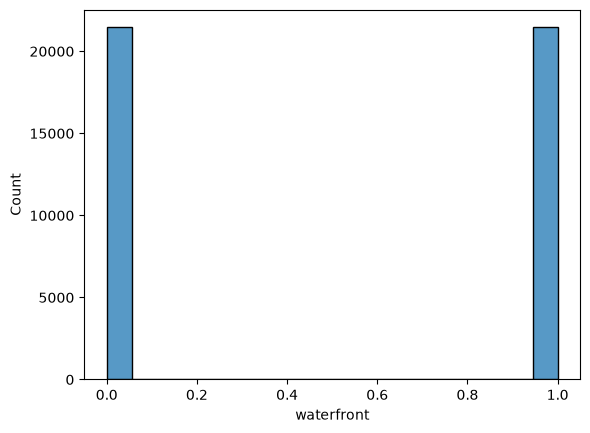

In [7]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()

X_resampled, y_resampled = smote.fit_resample(X, y)

# reconstruct the dataframe
df_oversampled_smote = pd.DataFrame(X_resampled)
df_oversampled_smote["waterfront"] = y_resampled

sns.histplot(df_oversampled_smote, x="waterfront")

In [8]:
df_oversampled_smote.shape

(42900, 23)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>WARNING</h3>

Notice how many more rows we created here? <strong style='color:orange ; background-color:black;'> We have to be VERY careful to ensure that our data still reflects reality. </strong>

In this case, we added WAY too many rows. Not everyone has a pool! And what's worse, synthetic data is really volatile. 

</div>